# Performance evaluation for **In Silico Combined Reference Genome**

## 0. Imports and path assignments

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import sys
import os
sys.path.append(os.path.abspath(os.path.join("..")))
from helper.visualization import *
from helper.metrics import * 

from warnings import simplefilter
simplefilter("ignore")

In [2]:
# --- Parameters ---
data_dir = Path("/omics/groups/OE0219/internal/altendorfer/epiproper/read_sorting_benchmark/data")
method = "icrg" # Add more methods here
fig_dir = Path.cwd() / "figures"
fig_dir.mkdir(exist_ok=True, parents=True)

## 1. Load data

In [3]:
df = read_evaluations(data_dir, method)
df.groupby(["Sample_Prefix", "Total_Reads"]).count()

ID  Mixture  \
Sample_Prefix                                      Total_Reads                
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000     54       54   
                                                   100000000    54       54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000     54       54   
                                                   100000000    54       54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000     54       54   
                                                   100000000    54       54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000     54       54   
                                                   100000000    54       54   

                                                                Replicate  \
Sample_Prefix                                      Total_Reads              
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000            54   
                                                   100000000           54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000            54   
                                                   100000000           54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000            54   
                                                   100000000           54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000            54   
                                                   100000000           54   

                                                                Human_Assigned  \
Sample_Prefix                                      Total_Reads                   
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   

                                                                Mouse_Assigned  \
Sample_Prefix                                      Total_Reads                   
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000                 54   
                                                   100000000                54   

                                                                Unmapped  \
Sample_Prefix                                      Total_Reads             
wgbs-human-brca-cl1_wgbs-mouse-bm-hsc1             20000000           54   
                                                   100000000          54   
wgbs-human-pancreas-organoid1_wgbs-mouse-pancre... 20000000           54   
                                                   100000000          54   
wgbs-human-pancreas-organoid2_wgbs-mouse-pancre... 20000000           54   
                                                   100000000          54   
wgbs-human-pancreas-organoid3_wgbs-mouse-pancre... 20000000           54   
                                                   100000000          54   

                                                                Human_Human  \
Sample_Prefix       

In [4]:
df["Human_Ratio"] = [float(s.rstrip('p')) for s in df["Mixture"]]

## Visualize assigned reads

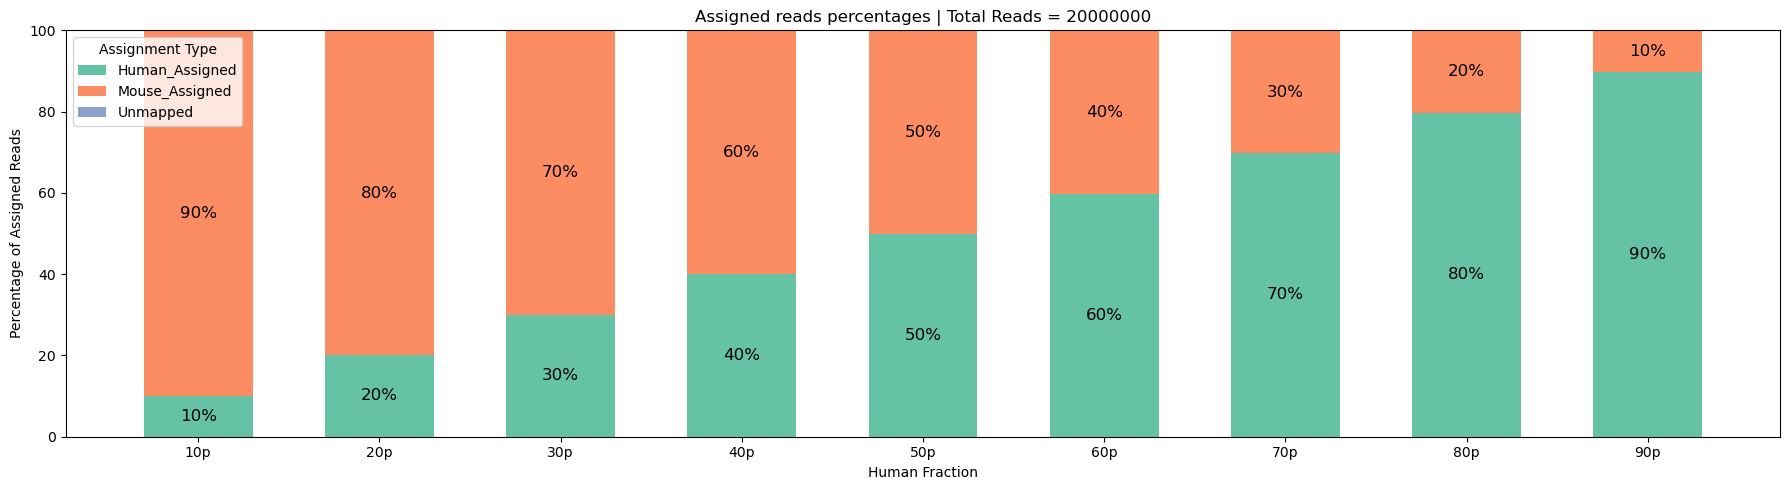

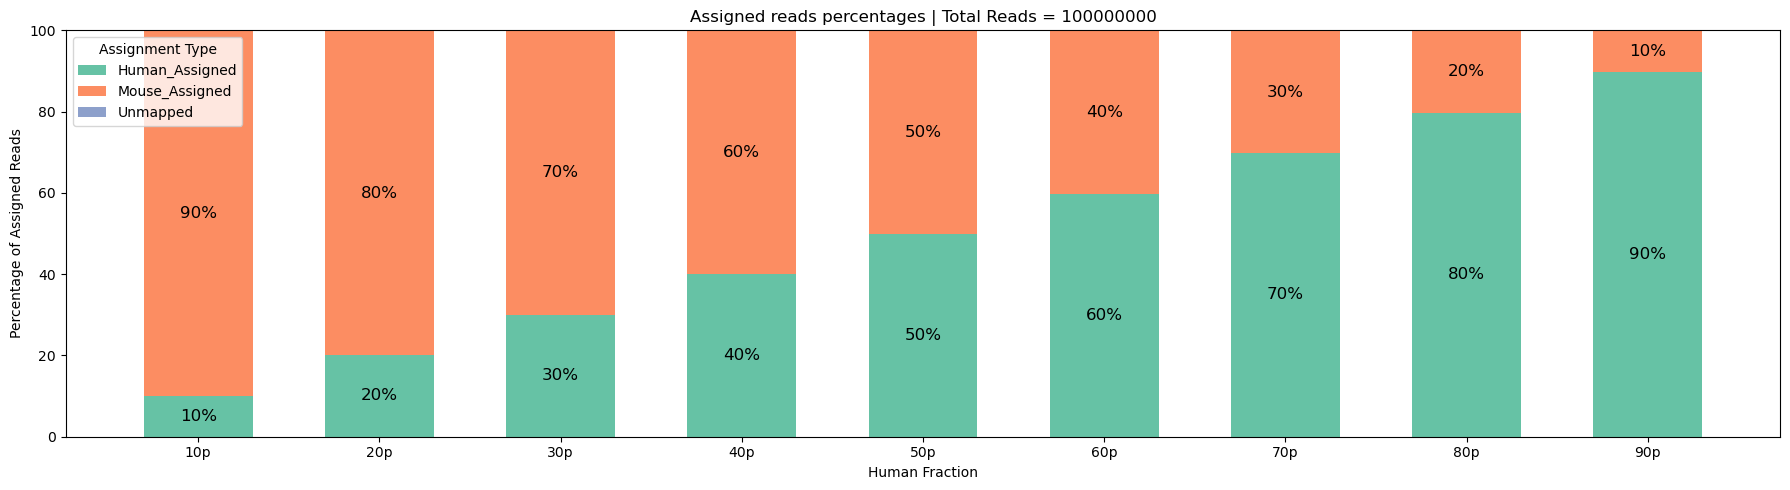

In [4]:
plot_assignment_bars_by_total_reads_stacked(df, assigned_cols=["Human_Assigned", "Mouse_Assigned", "Unmapped"])

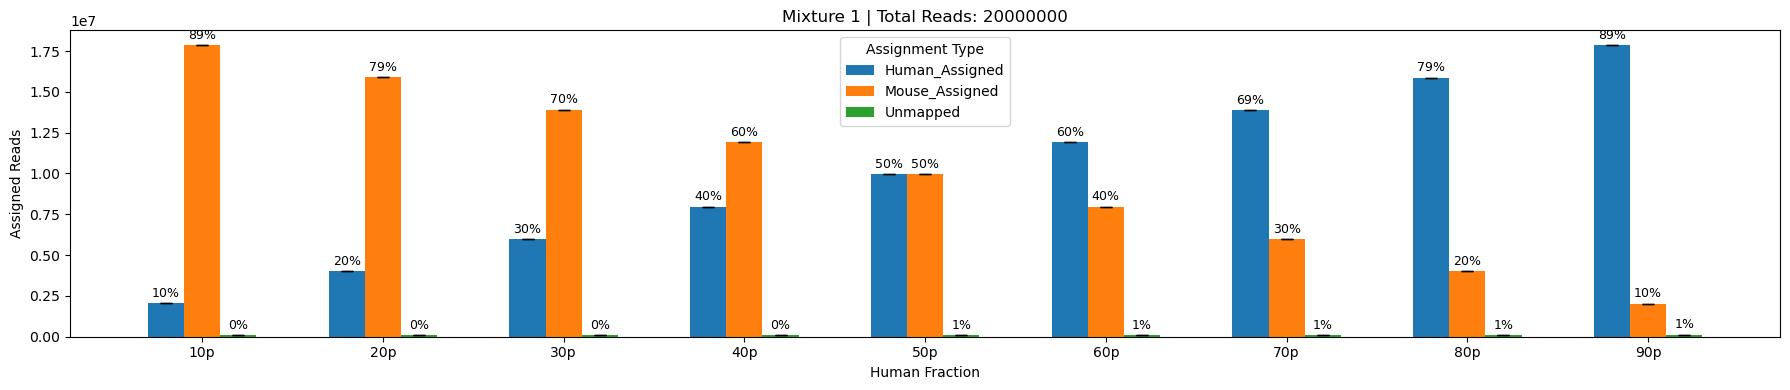

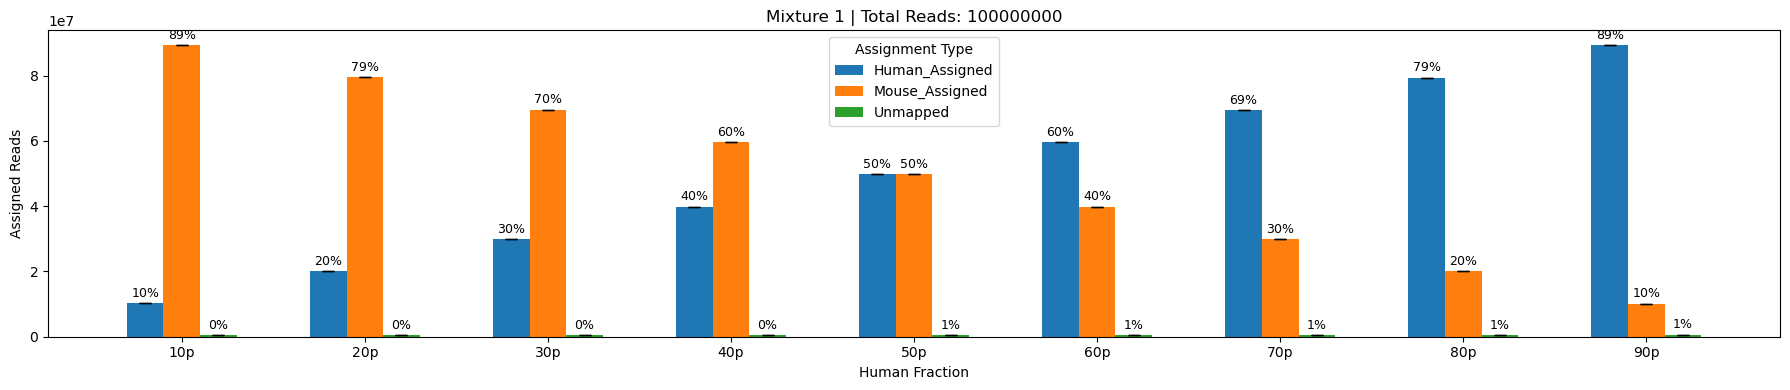

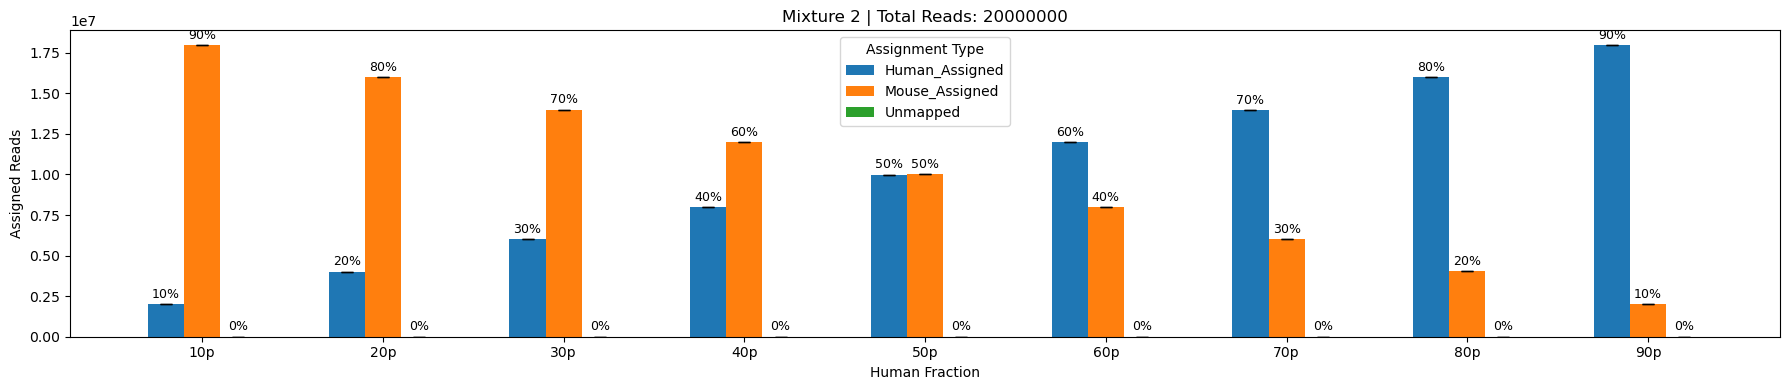

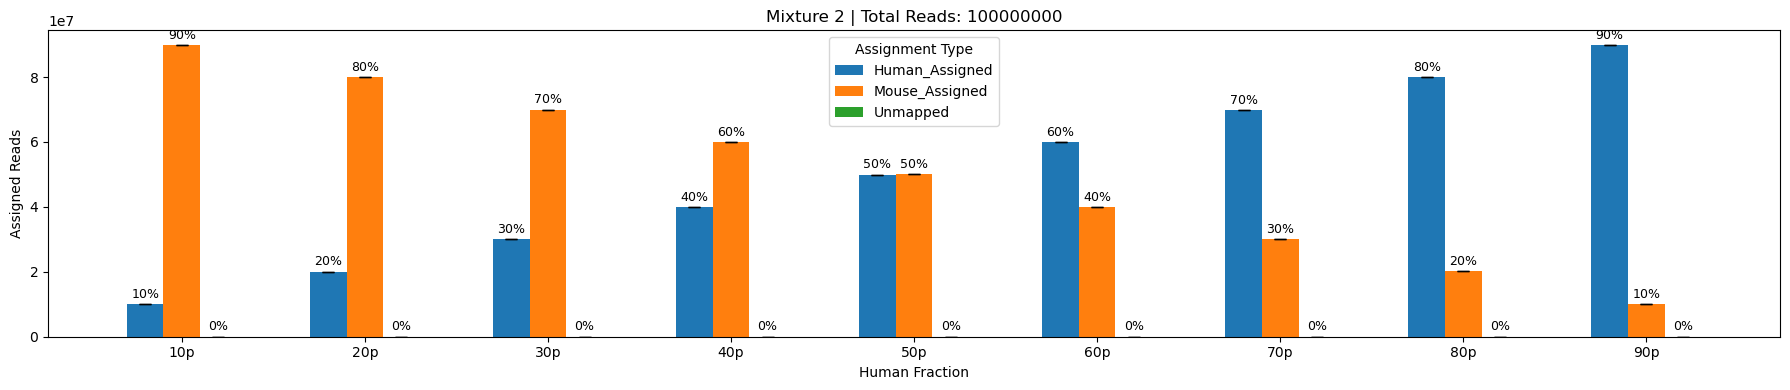

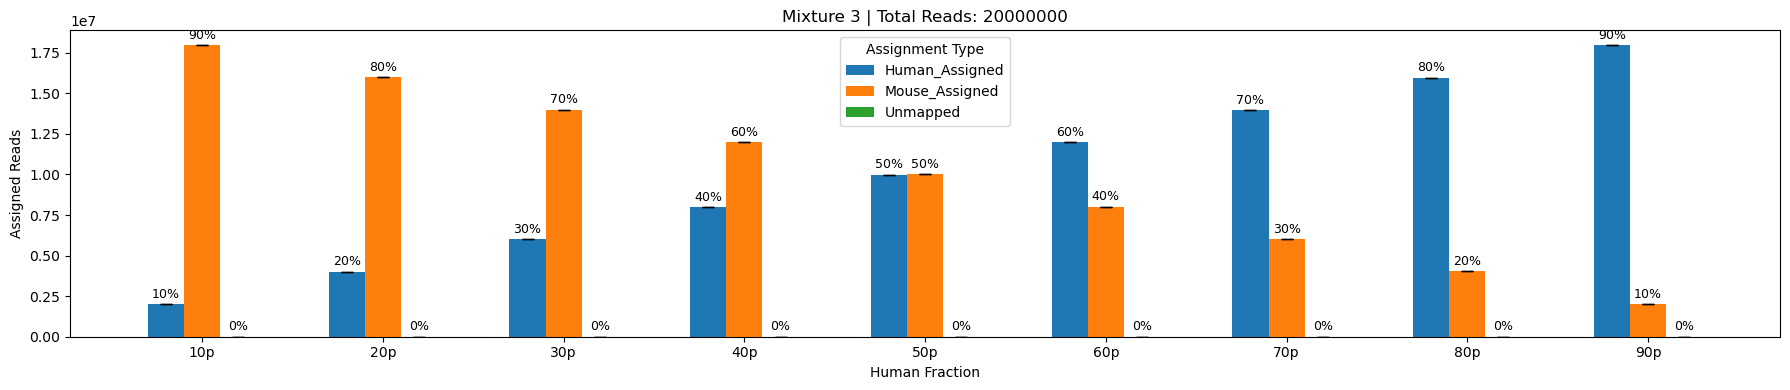

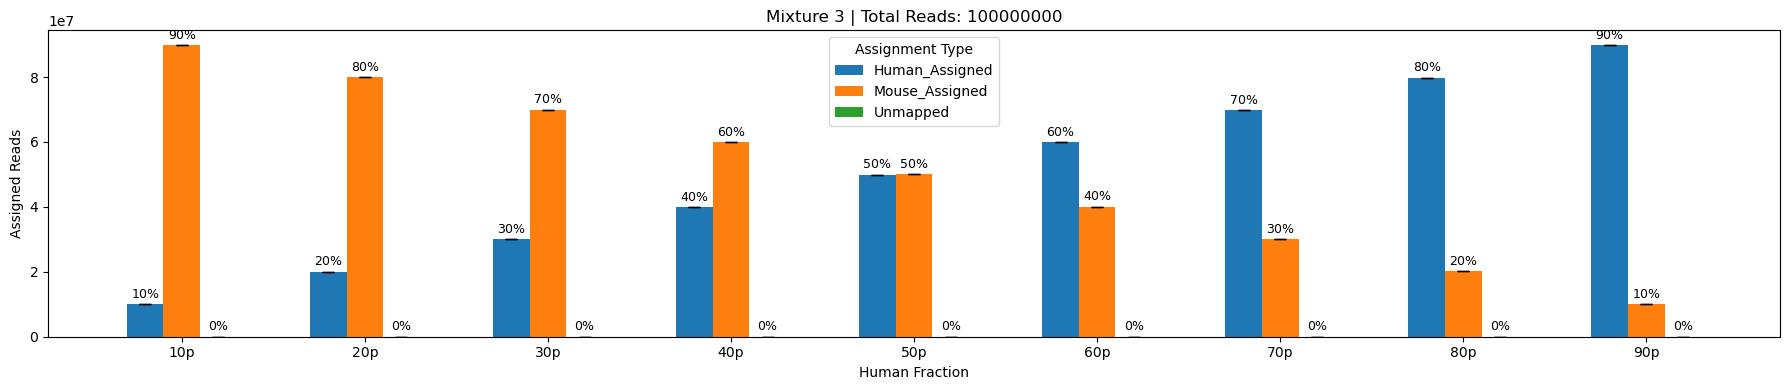

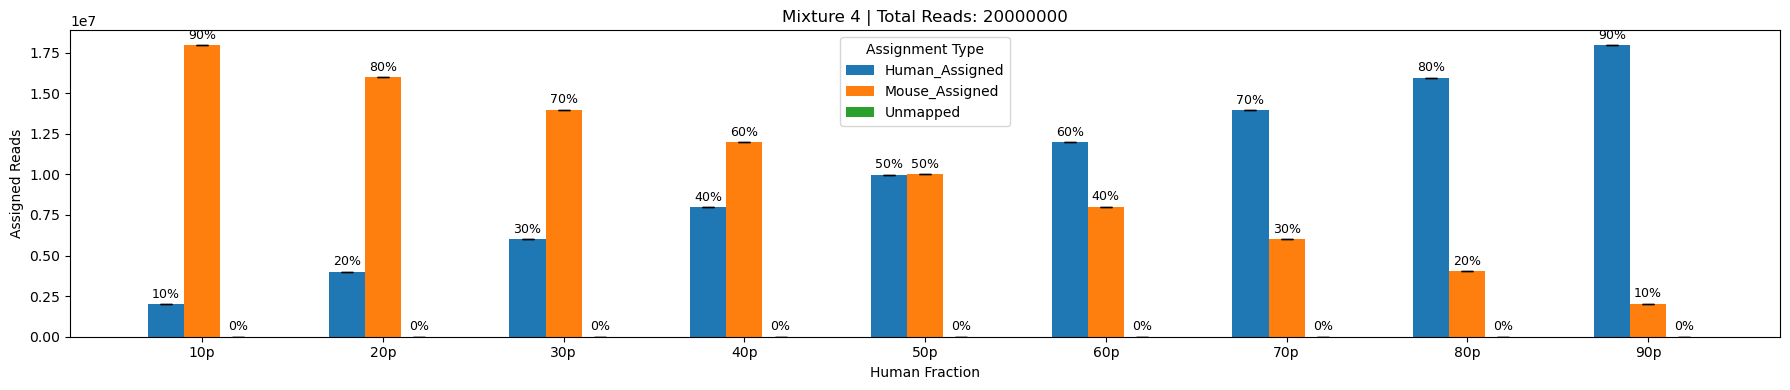

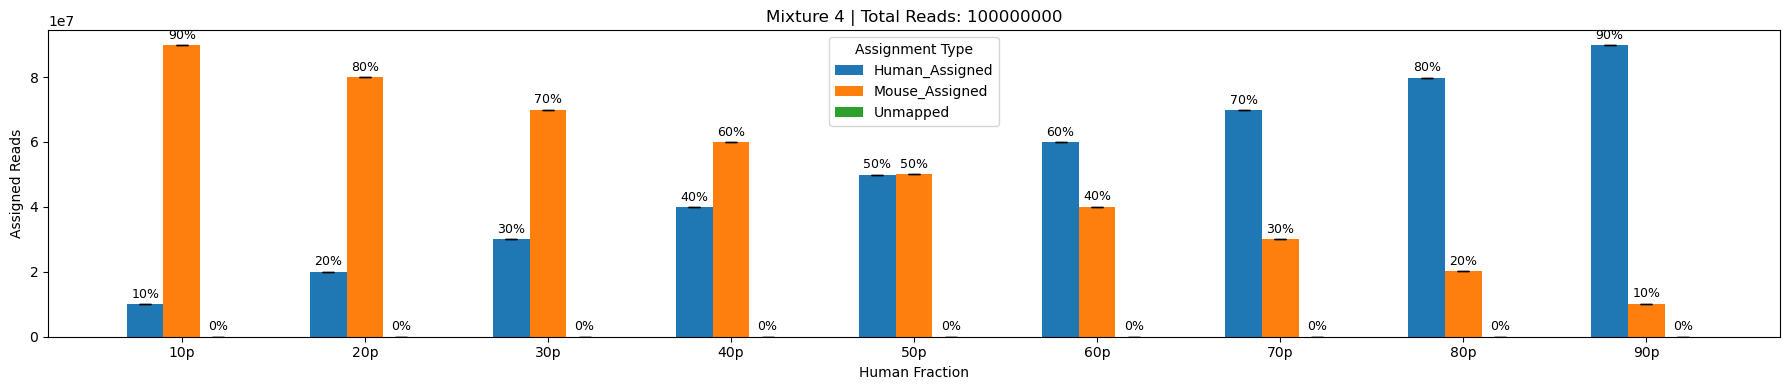

In [5]:
plot_assignment_bars(df, assigned_cols=["Human_Assigned", "Mouse_Assigned", "Unmapped"], save=True, fig_dir=fig_dir)

## Confusion Matrix

In [6]:
df = assign_confusion_matrix(df, method="icrg")

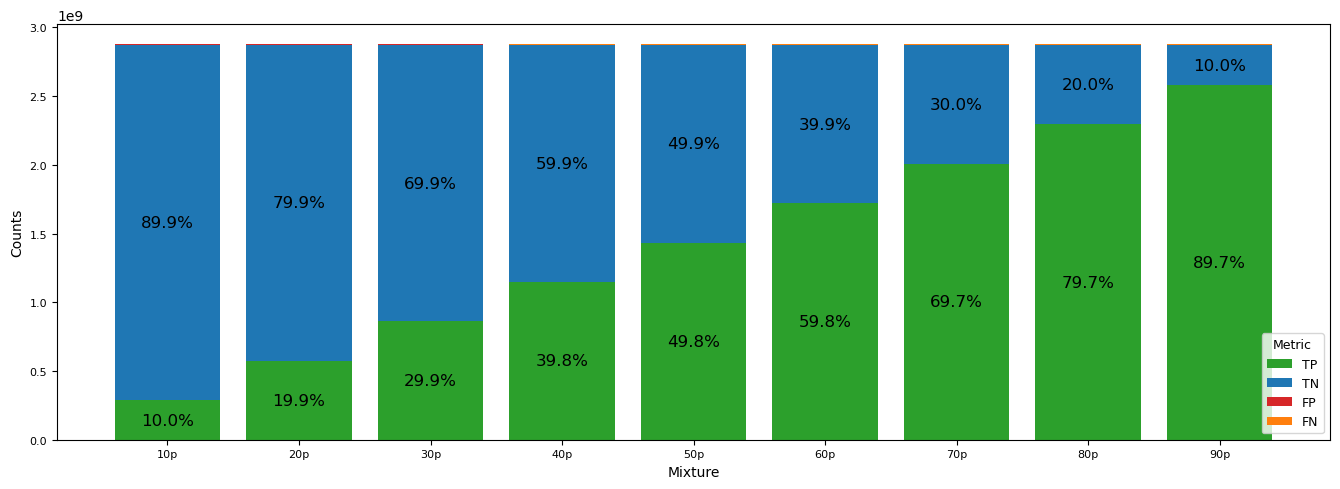

In [7]:
plot_stacked_confusion_bar(
    df,
    save=True,
    fig_dir=fig_dir
)

## Calculate performance metrics

In [8]:
df_metrics = calculate_metrics(df)
df_metrics.head(3)

,ID,Sample_Prefix,Total_Reads,Mixture,Replicate,Human_Assigned,Mouse_Assigned,Unmapped,Human_Human,Human_Mouse,...,Recall,FPR,Precision,F1,MCC,Human_Loss,Contamination_Rate,Mouse_Leakage,Human_Ratio,Score
0,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,0,13971891,6021753,6356,13964878,7013,...,0.997491,0.001169,0.999498,0.998494,0.994996,0.002509,0.000502,0.001169,0.7,0.998896
1,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,1,13972603,6021008,6389,13965693,6910,...,0.997549,0.001152,0.999505,0.998527,0.995105,0.002450,0.000495,0.001152,0.7,0.998919
2,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,wgbs-human-pancreas-organoid3_wgbs-mouse-pancr...,20000000,70p,2,13972102,6021527,6371,13965034,7068,...,0.997502,0.001178,0.999494,0.998497,0.995008,0.002498,0.000506,0.001178,0.7,0.998897


## Visualize performance metrics

### By total reads, for each sample

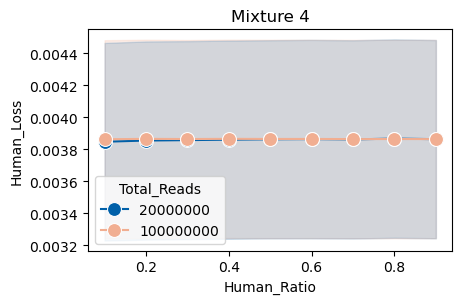

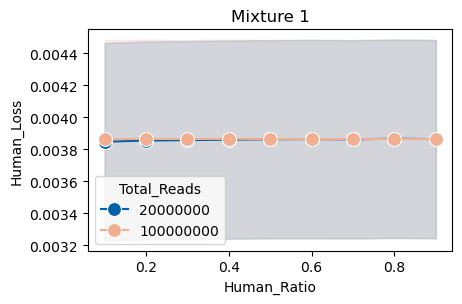

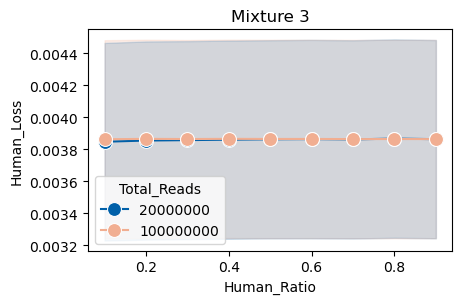

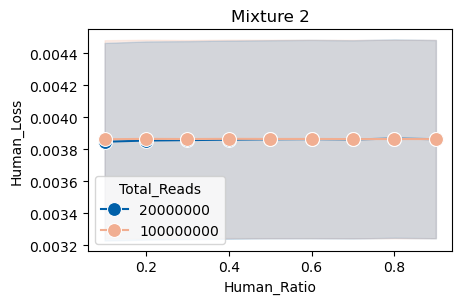

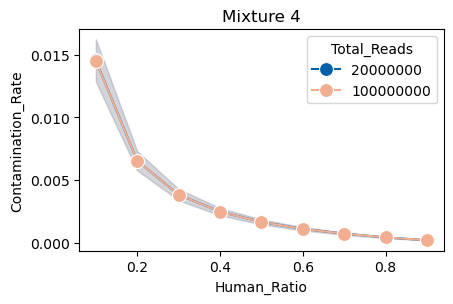

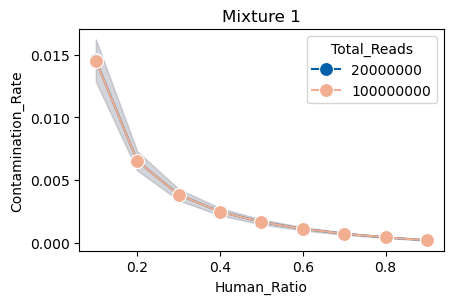

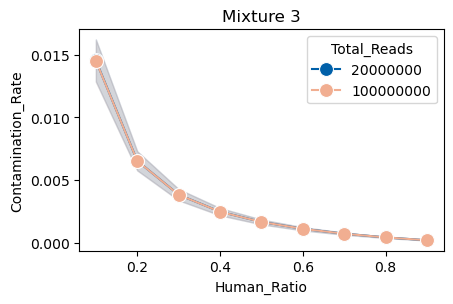

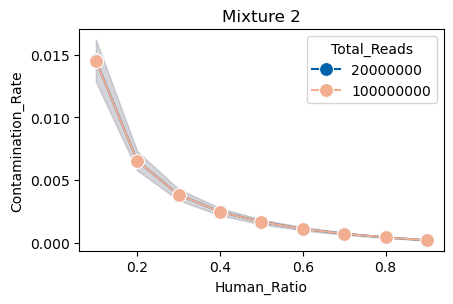

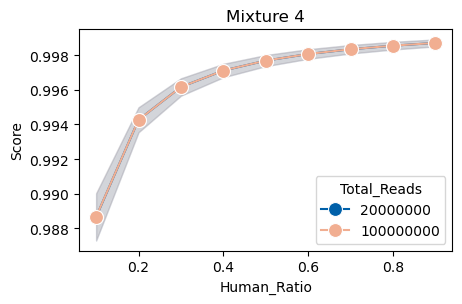

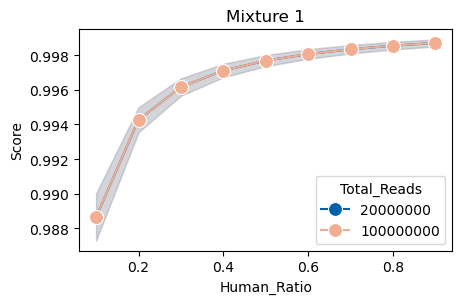

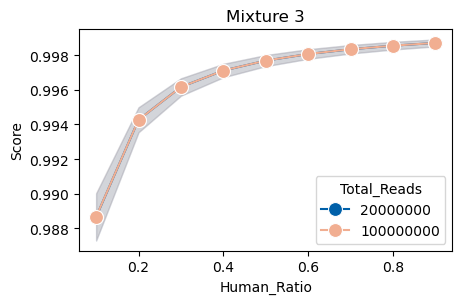

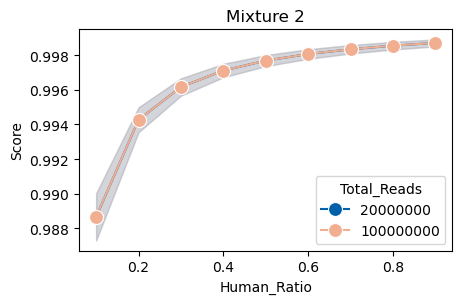

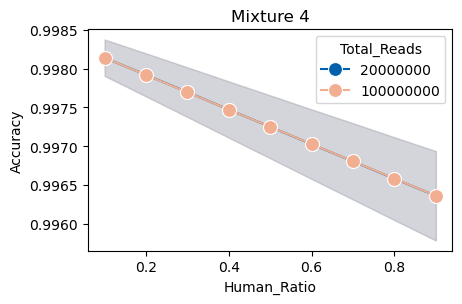

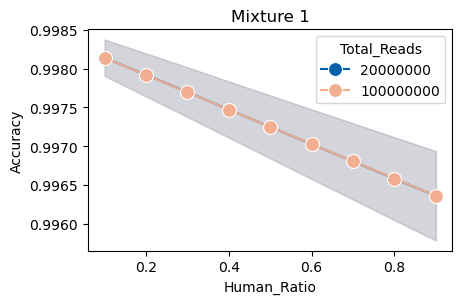

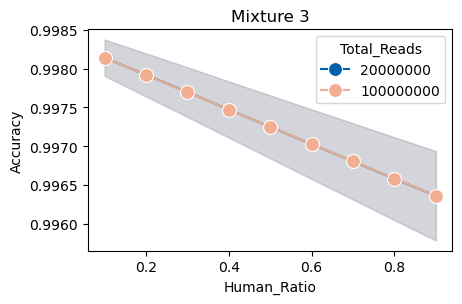

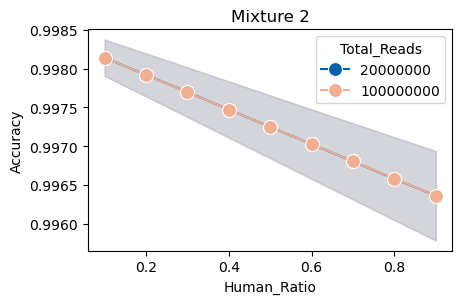

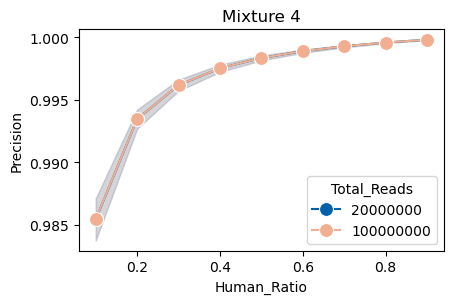

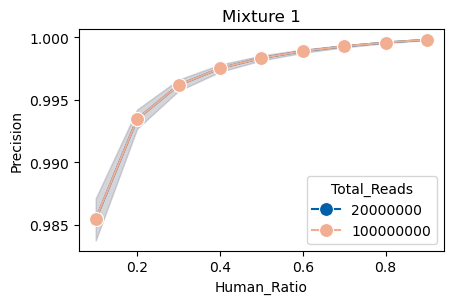

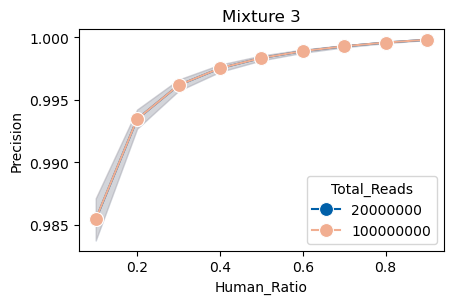

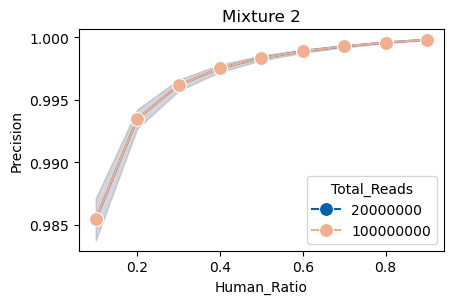

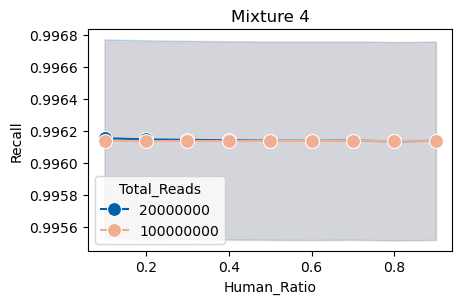

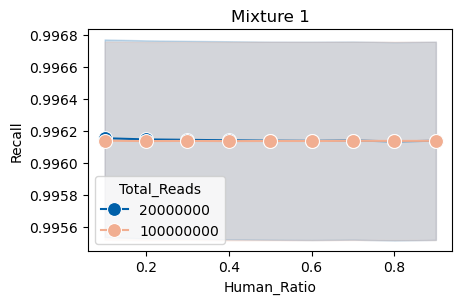

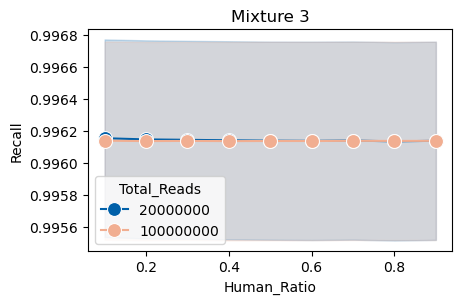

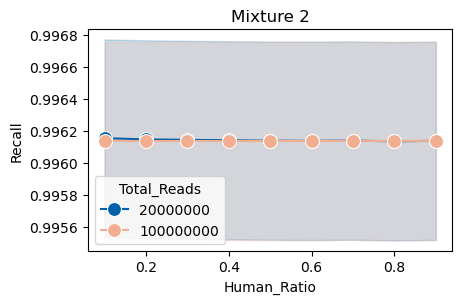

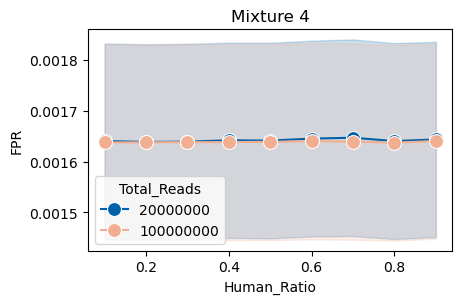

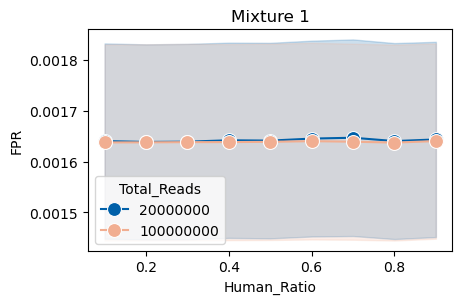

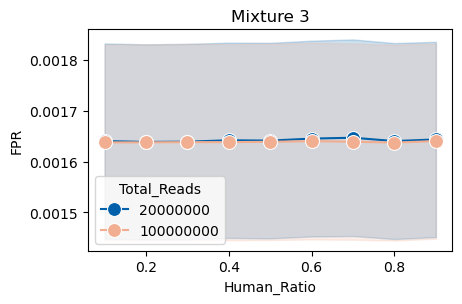

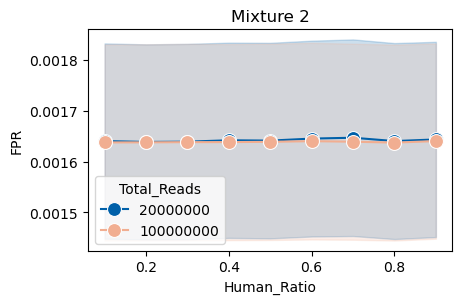

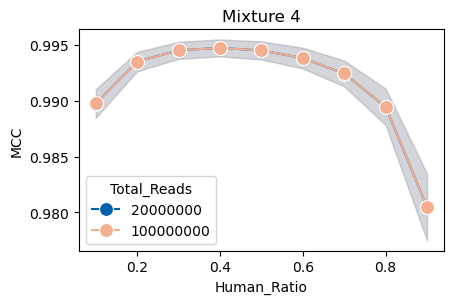

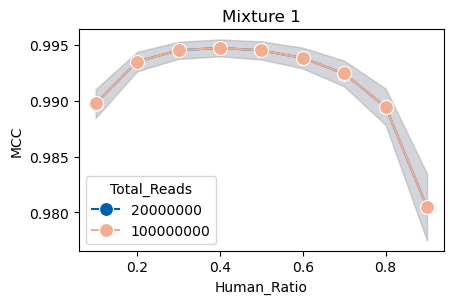

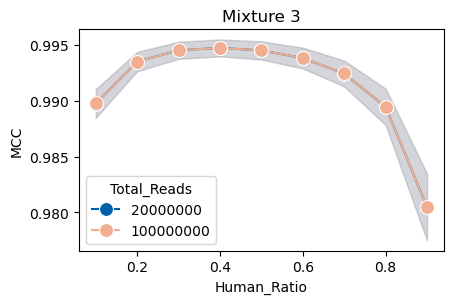

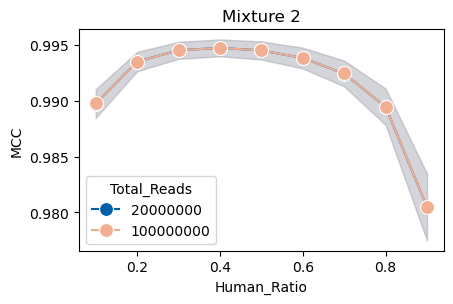

In [9]:
figsize=mm_to_inches((120, 80))
metrics = ["Human_Loss", "Contamination_Rate", "Score", "Accuracy", "Precision", "Recall", "FPR", "MCC"]
for metric in metrics:
    errorplot_by_reads(df_metrics, metric=metric, figsize=figsize, save=True, fig_dir=fig_dir, palette=dkfz_colors)



### Across samples

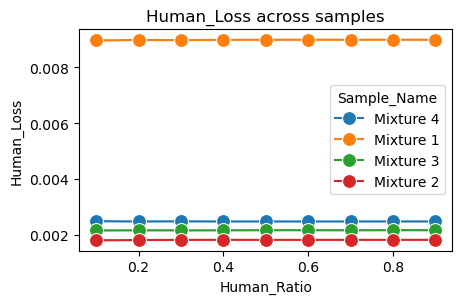

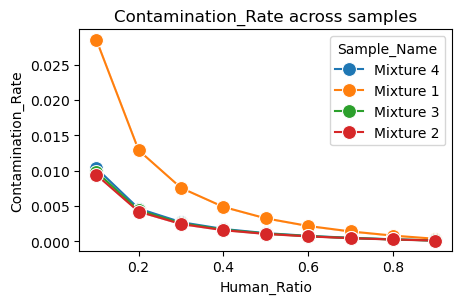

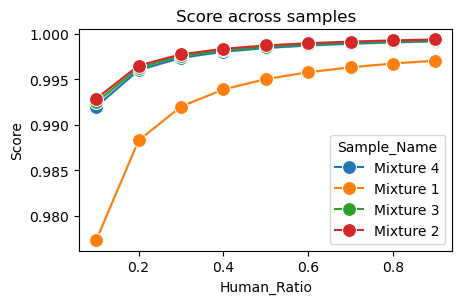

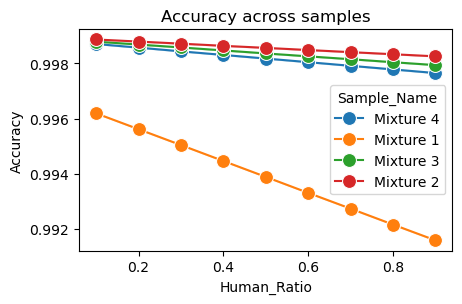

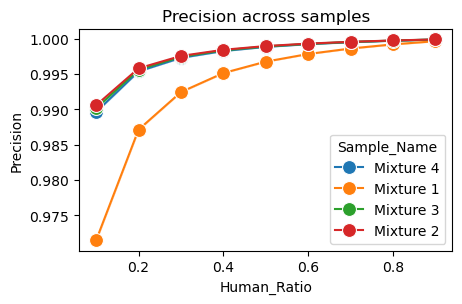

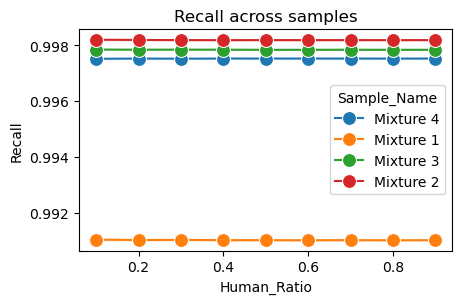

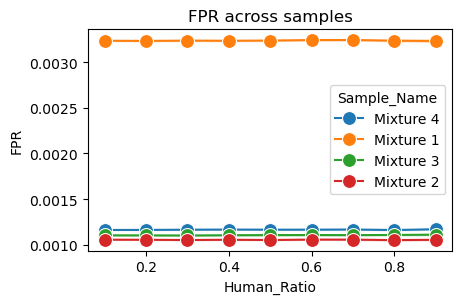

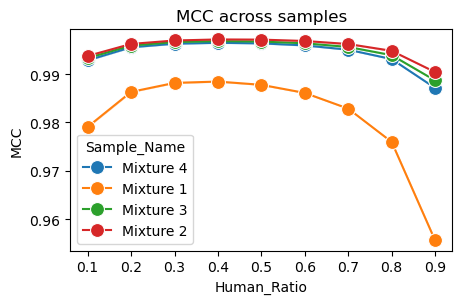

In [10]:
for metric in metrics:
    errorplot_by_sample(df_metrics, metric=metric, figsize=figsize)


### Boxplots across samples

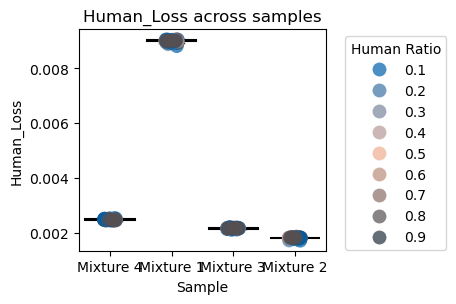

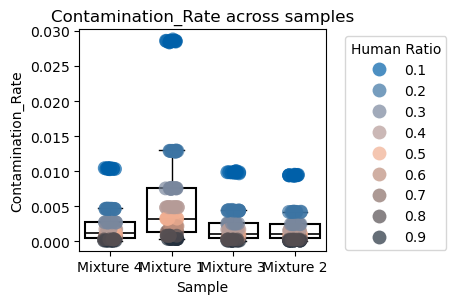

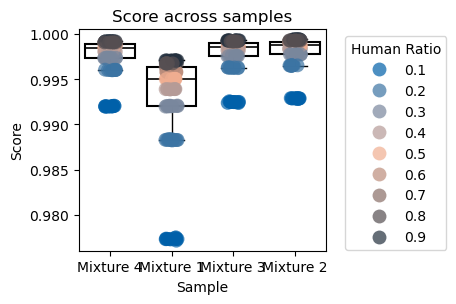

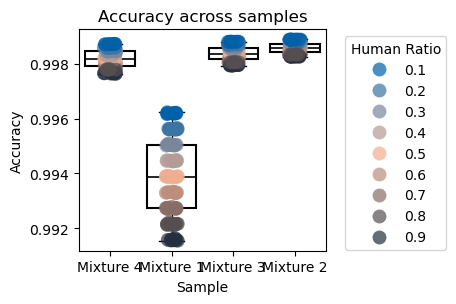

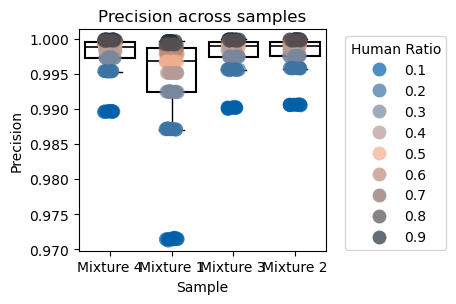

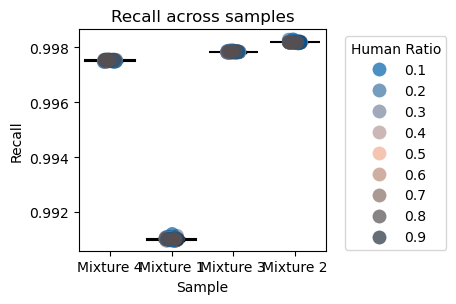

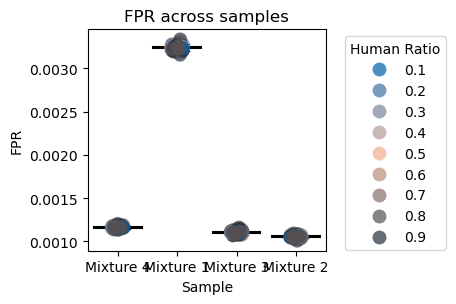

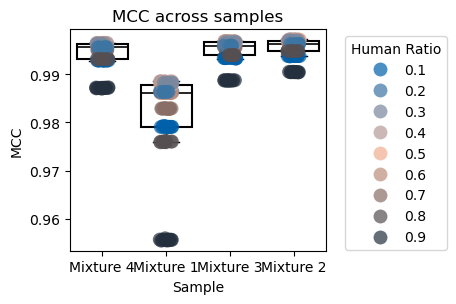

In [11]:
for metric in metrics:
    boxplot_by_samples(df_metrics, metric=metric, figsize=figsize)


## Save dataframe

In [12]:
df_metrics["Method"] = "ICRG"

In [13]:
out_dir = Path.cwd() / "results"
out_dir.mkdir(exist_ok=True)

df_metrics.to_csv(out_dir / "icrg.csv", index=False)